# 00 · Check the raw data

**Goal:** make sure we can load the recordings and that they look like real EEG. We do this before any machine learning.

**How it fits the project:** the project asks whether published ADHD-vs-control EEG accuracies survive a split by participant. That question only makes sense if the data itself is sound. Think of it like calibrating a lab instrument before an experiment. If the readings are off, every later result is off too.

In this notebook we:
1. count the files and look inside one `.mat` file,
2. check the value range (units),
3. plot one participant's EEG and its frequency spectrum,
4. see where on the head the alpha rhythm is strongest and which channels look noisy.

Everything after step 1 uses **one participant only** (`v10p`, ADHD). These are checks, not group results.

**Question:** How many recordings do we have, and what is inside one `.mat` file?

**How:**
1. `Path(...).glob("*.mat")` lists all MATLAB files in the `ADHD` and `Control` folders. We count them.
2. `loadmat` (from SciPy) reads a MATLAB file into a Python dictionary.
3. MATLAB adds bookkeeping entries whose names start with `__`. We skip these and keep the one real data variable.
4. `x.shape` gives (number of samples, number of channels). Dividing samples by the sampling rate (128 samples per second) gives the length in seconds.

**What we found:** 61 ADHD files and 60 Control files, so 121 recordings in total. The first ADHD file, `v10p.mat`, holds one variable called `v10p` with shape (14304, 19): 14 304 time samples × 19 channels, i.e. 111.75 s. Rows are time and columns are channels. MNE expects the opposite (channels × samples), which is why later code uses `x.T` (transpose). *Assumption:* one file = one participant. Notebook 01 checks that the IDs are unique.

In [1]:
from pathlib import Path
from scipy.io import loadmat

ROOT = Path(r"C:\data\eeg\adhd")
for group in ["ADHD", "Control"]:
    files = sorted((ROOT / group).glob("*.mat"))
    print(group, len(files), "files")

f = sorted((ROOT / "ADHD").glob("*.mat"))[0]
m = loadmat(f)
keys = [k for k in m if not k.startswith("__")]
x = m[keys[0]]
print(f.name, "variable:", keys, "shape:", x.shape, "seconds:", x.shape[0] / 128)

ADHD 61 files
Control 60 files
v10p.mat variable: ['v10p'] shape: (14304, 19) seconds: 111.75


**Question:** Are the numbers plausible for EEG, and what do this participant's signal and spectrum look like?

**How:**
1. Print the minimum, maximum and standard deviation (spread) of all values. This is a quick check on the units.
2. `mne.create_info` describes the recording: channel names, sampling rate (128 Hz) and channel type (EEG).
3. `mne.io.RawArray` wraps the NumPy array into an MNE "Raw" object. `x.T` puts channels first. `* 1e-6` converts µV to volts, because MNE works in volts internally.
4. `set_montage("standard_1020")` looks up each electrode name (Fp1, Cz, ...) in the international 10-20 system and gives it a position on the head. This is used for the small head maps in the plots.
5. `raw.plot` draws the first 10 s of every channel as wavy traces.
6. `compute_psd(fmax=50).plot()` computes and plots the **power spectral density (PSD)**: how much signal power there is at each frequency. MNE uses the **Welch method** by default. It cuts the signal into overlapping segments, takes the Fourier transform of each, and averages them. Averaging gives a smoother, more reliable spectrum, like averaging repeated measurements in the lab. Power is shown in dB (a log scale).

**What we found:** min −2208, max 4802, standard deviation 164. The file does not state units. **We assume µV.** That is the usual unit for EEG and matches the comment in `src/load.py`. A spread of 164 µV is large for scalp EEG (often tens of µV). Values in the thousands point to artifacts such as EOG (eye-movement) artifacts or slow drifts. In the trace plot, Fp1 (just above the left eye) has big slow swings at the start, which fits an EOG (eye-movement) artifact (an interpretation). The spectrum falls as frequency rises (the usual "1/f" shape), with a bump near 10 Hz (alpha) on some channels. There is a sharp rise exactly at the 50 Hz right edge of the plot. This is **most likely 50 Hz mains (power-line) noise**. The plot stops at 50 Hz, so it cannot show what happens above 50 Hz. The `FutureWarning` only says the montage name will change in a later MNE version. It does not affect the result.

min/max/std: -2208.0 4802.0 163.76943629124273
Creating RawArray with float64 data, n_channels=19, n_times=14304
    Range : 0 ... 14303 =      0.000 ...   111.742 secs
Ready.


C:\Users\Rajesh Sampathkumar\AppData\Local\Temp\ipykernel_17760\540110058.py:9: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  raw.set_montage("standard_1020")           # electrode positions from the names


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


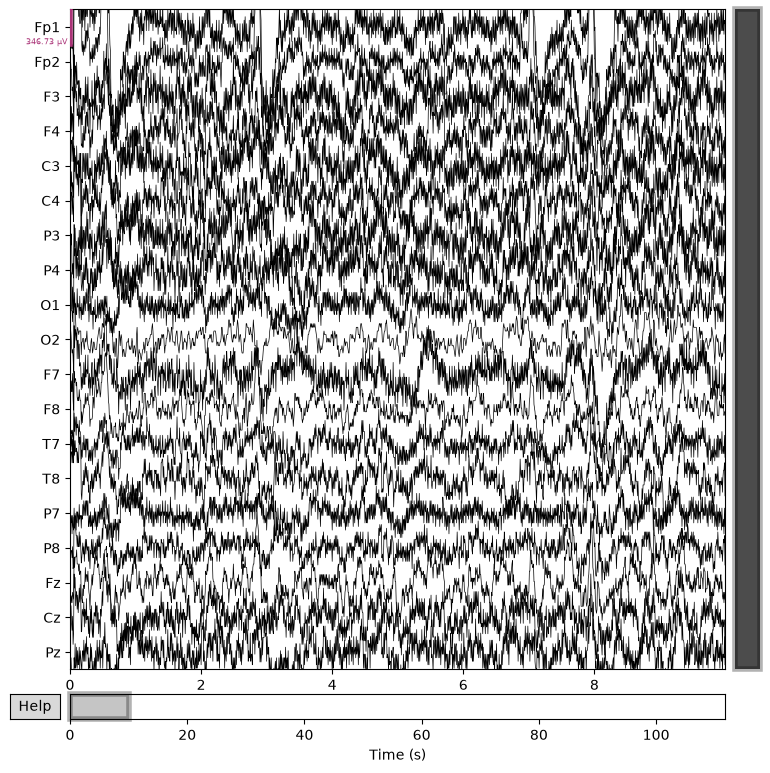

Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


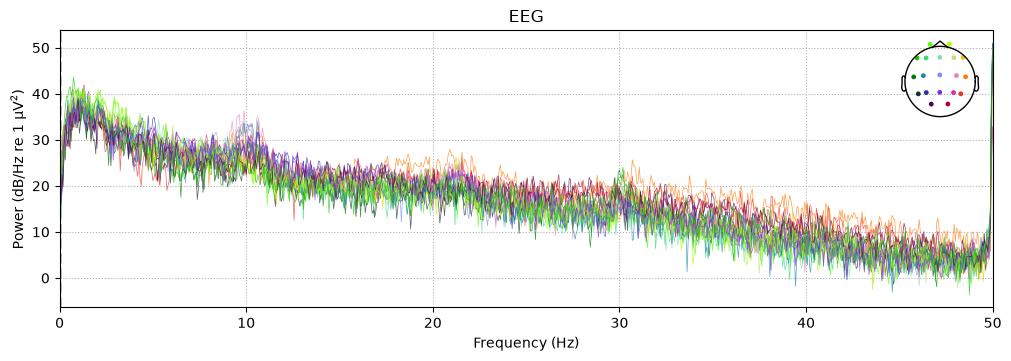

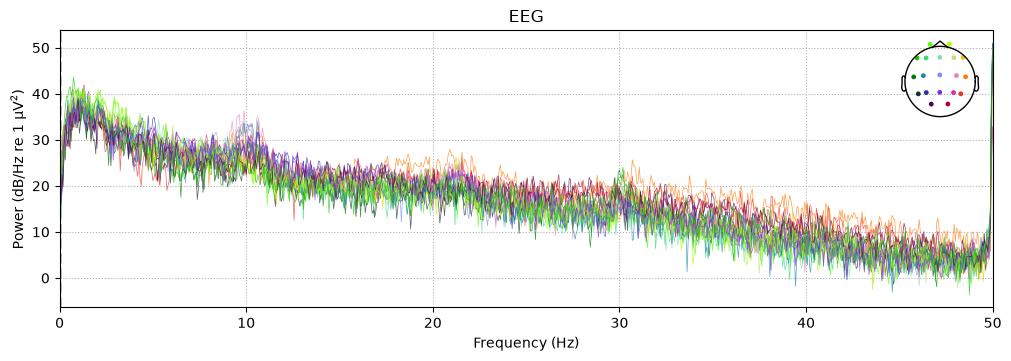

In [2]:
import sys; sys.path.append("..")          # so the notebook can find src/
from src.channels import CHANNELS, SFREQ
import mne

print("min/max/std:", x.min(), x.max(), x.std())   # units check

info = mne.create_info(CHANNELS, SFREQ, ch_types="eeg")
raw = mne.io.RawArray(x.T * 1e-6, info)    # MNE wants channels x samples, in volts
raw.set_montage("standard_1020")           # electrode positions from the names
raw.plot(duration=10, scalings="auto")
raw.compute_psd(fmax=50).plot()

**Question:** What does the signal look like after removing slow drift and high-frequency noise?

**How:**
1. `raw.copy()` makes a copy, so the original stays untouched.
2. `.filter(l_freq=1.0, h_freq=40.0)` applies a **band-pass filter** that keeps 1–40 Hz. Below 1 Hz there is mostly slow drift (sweat, electrode movement). Above 40 Hz there is mostly EMG (muscle) and mains noise. A filter works like a sieve that keeps only the middle-sized grains.
3. MNE's log shows it is a *zero-phase FIR* filter. Zero-phase means waves are not shifted in time. The −6 dB edges sit at 0.5 Hz and 45 Hz.
4. Plot the traces and the PSD again.

**What we found:** The traces are steadier, with less slow wandering. The spectrum now drops steeply above 40 Hz, to about −30 dB near 49 Hz. A narrow spike is still visible exactly at 50 Hz. This supports the mains-noise idea: a very strong single-frequency noise can partly survive the filter. This same 1–40 Hz filter is used in `src/features.py`, so the features in notebooks 02 and 03 use this cleaned signal.

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 423 samples (3.305 s)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


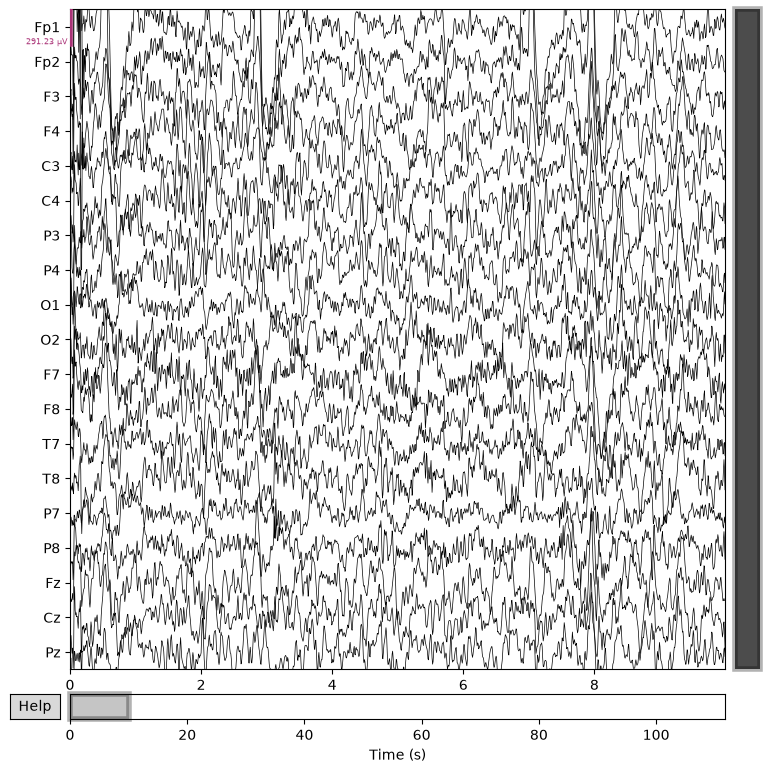

Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


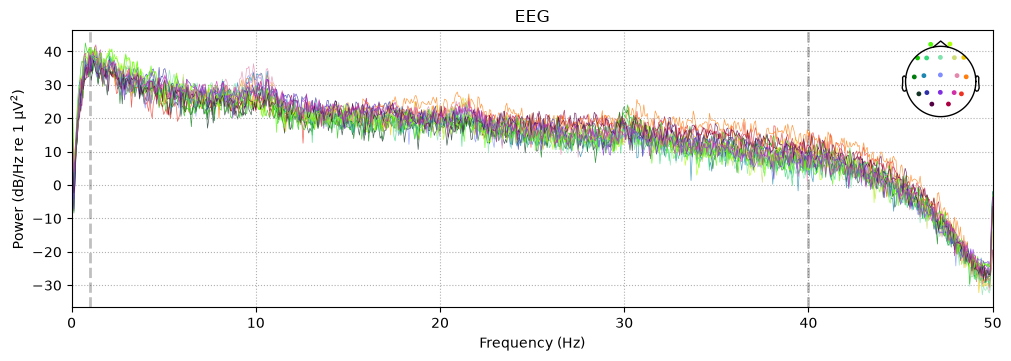

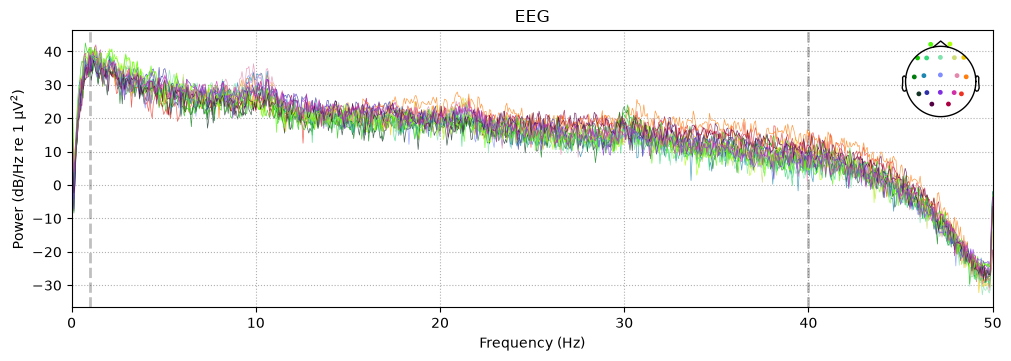

In [6]:
raw_f = raw.copy().filter(l_freq=1.0, h_freq=40.0)
raw_f.plot(duration=10, scalings="auto")
raw_f.compute_psd(fmax=50).plot()

**Question:** Where on the head is the alpha rhythm strongest, and are any channels unusually noisy at high frequencies?

**How:**
1. Compute the PSD of the filtered signal from 1 to 40 Hz. `get_data(return_freqs=True)` returns the power array (channels × frequencies) and the list of frequencies.
2. `* 1e12` converts V²/Hz to µV²/Hz, since (10⁶)² = 10¹².
3. True/False masks select two frequency ranges: alpha (7–13 Hz) and "high" (17–40 Hz). Note: here alpha is 7–13 Hz, while `src/features.py` uses 8–13 Hz.
4. For each channel, a small table gives: the frequency with the most power inside 7–13 Hz (`alpha_peak_Hz`), the mean alpha power, and the mean 17–40 Hz power. It is sorted by alpha power.
5. Two extra PSD plots: back-of-head channels (O1, O2, P3, P4, Pz) and front channels (Fp1, Fp2, F7, F8).

**What we found:** Alpha is strongest at **C4 (936), C3 (652) and Cz (604) µV²/Hz**, along the central strip over the motor cortex. The peaks are near 10 Hz. This fits the **mu rhythm**, an alpha-band rhythm over motor areas (an interpretation). The back-of-head channels O1/O2 (284/344) are low. With eyes closed, alpha is usually strongest there. The posterior PSD plot shows no clear alpha peak. A likely reason: the participants were doing a visual task with eyes open (per the dataset description), and looking at things suppresses posterior alpha. **T8 has 131 µV²/Hz at 17–40 Hz**, about double the next channel (P8, 76). T8 sits above the right ear, over the temporalis (jaw) muscle. EMG activity adds broad high-frequency power, so this is **likely an EMG (jaw-muscle) artifact**, though not proven. For Fp1, Fp2 and O2, the "alpha peak" sits at the bottom of the range (7.4–7.9 Hz). There is probably no real peak there: power falls with frequency, so the largest value is simply at the lowest frequency.

Effective window size : 16.000 (s)
   channel  alpha_peak_Hz  alpha_power  power_17_40Hz
5       C4           9.88       936.36          53.92
4       C3          10.62       651.52          31.17
17      Cz           9.88       604.38          39.26
7       P4          10.62       552.86          51.23
13      T8           9.88       550.18         131.29
6       P3          10.62       545.79          55.72
18      Pz          10.62       514.85          47.33
16      Fz           8.19       498.35          41.25
3       F4          10.62       489.88          48.49
2       F3          10.06       406.94          36.47
9       O2           7.88       344.28          68.09
0      Fp1           7.81       336.41          33.48
11      F8           8.31       332.98          60.44
1      Fp2           7.44       330.15          35.74
12      T7          10.06       308.59          37.04
15      P8           9.56       307.39          75.66
8       O1           9.56       284.09         

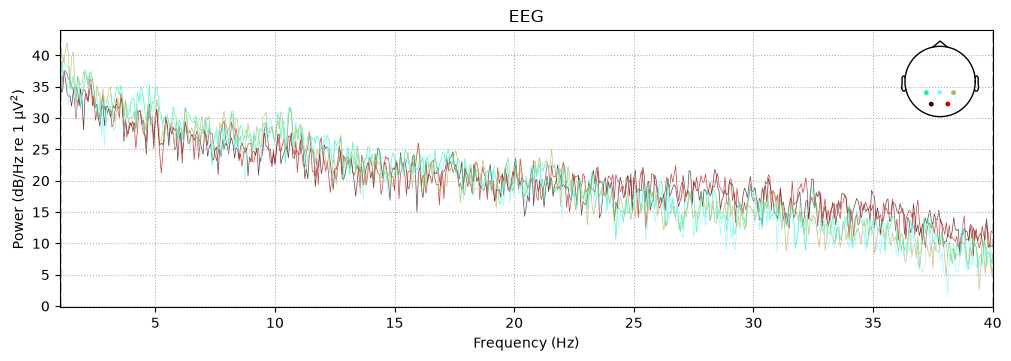

Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


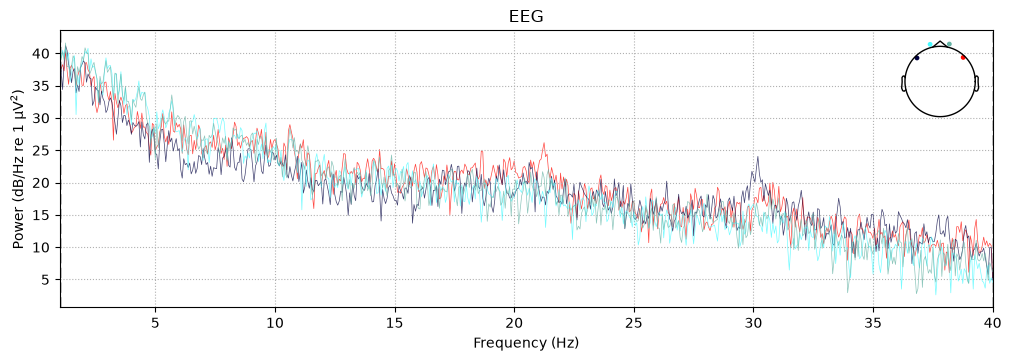

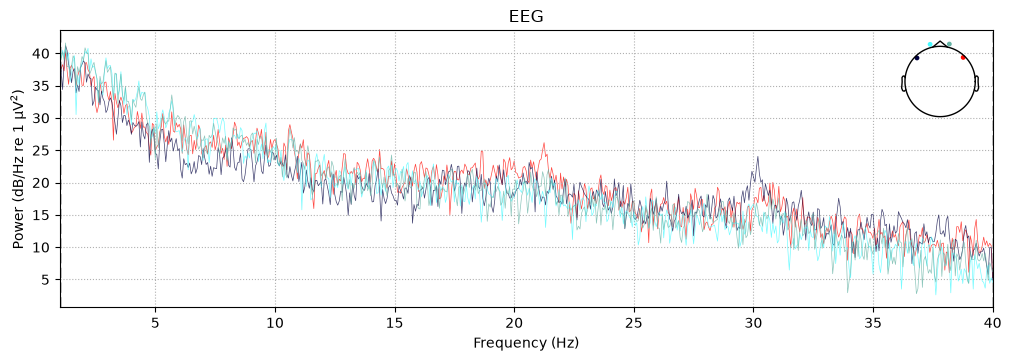

In [5]:
import numpy as np, pandas as pd

psd = raw_f.compute_psd(fmin=1, fmax=40)
p, f = psd.get_data(return_freqs=True)
p = p * 1e12                                   # V²/Hz -> µV²/Hz

alpha = (f >= 7) & (f <= 13)
high  = (f >= 17) & (f <= 40)
table = pd.DataFrame({
    "channel": CHANNELS,
    "alpha_peak_Hz": f[alpha][p[:, alpha].argmax(axis=1)],
    "alpha_power":   p[:, alpha].mean(axis=1),
    "power_17_40Hz": p[:, high].mean(axis=1),
}).round(2)
print(table.sort_values("alpha_power", ascending=False))

raw_f.compute_psd(fmin=1, fmax=40, picks=["O1", "O2", "P3", "P4", "Pz"]).plot()   # back of head
raw_f.compute_psd(fmin=1, fmax=40, picks=["Fp1", "Fp2", "F7", "F8"]).plot()      # front

## Key takeaways
- All 121 files load (61 ADHD, 60 Control), each with 19 channels at 128 Hz.
- Values are large (std 164, range −2208 to 4802; **assumed µV**). This suggests EOG (eye-movement) artifacts.
- For this participant, alpha is strongest over the centre of the head (likely mu rhythm) and weak at the back, which fits a visual task.
- T8 shows extra 17–40 Hz power, likely an EMG (jaw-muscle) artifact. Artifacts like this differ between participants, and a classifier can learn them.
- A 1–40 Hz band-pass removes drift and most mains noise. The same filter is used for all features.

## Open questions
- Are the units really µV? Check the dataset documentation.
- Is the spike at 50 Hz mains noise, and was the data filtered by the provider? Plot the PSD up to 64 Hz (the Nyquist frequency, half of 128 Hz) to see.
- There is a small bump near 30 Hz in the raw spectrum. Is it a real rhythm or an artifact?
- How common are EMG (T8) and EOG (Fp1/Fp2) artifacts across all 121 participants, and do they differ between ADHD and Control?
- Does the central-alpha pattern hold for other participants, or only for `v10p`?